# Lab Assignment 4: Building and Evaluating N-gram Language Models

**Student:** Muhammad Obaidullah (abdulsalam.m@northeastern.edu)  
**Course:** Applied NLP  
**Submission:** Upload `Lab_4.ipynb` to Canvas with all cells run and outputs visible.

---

## Overview

An n-gram language model assigns probabilities to sequences of words. It is among the simplest statistical models of language, yet it embeds a fundamental assumption — the **Markov assumption** — that has shaped the design of every language model since. Understanding where n-gram models succeed, where they fail, and how smoothing repairs their worst failure mode (zero probability for unseen sequences) gives you the conceptual foundation needed to understand why neural language models are built the way they are.

In this lab you will implement unigram, bigram, and trigram models using maximum likelihood estimation, evaluate them with perplexity, measure how the choice of n trades coverage against sparsity, and apply two smoothing techniques — Laplace and Kneser-Ney — comparing their effects on held-out perplexity.

---

## A note on logarithms

All log-probability calculations in this lab use **log base 2**, consistent with J&M Chapter 3. This choice is conventional in information theory (probabilities become bits) and matches the perplexity formula as defined in the textbook:

$$\text{PP}(W) = 2^{-\frac{1}{N}\sum_{i=1}^{N}\log_2 P(w_i \mid w_{i-1})}$$

If you use `math.log` or `np.log` (natural log) instead of `math.log2` or `np.log2`, your perplexity values will be numerically different from the expected outputs and your tests will fail. Use `math.log2` or `np.log2` throughout.

---

## Learning Objectives

By the end of this lab you will be able to:

1. Implement n-gram language models and calculate sequence probabilities using maximum likelihood estimation
2. Evaluate language model quality using perplexity and explain its relationship to prediction uncertainty
3. Analyze the Markov assumption and assess how the choice of n creates trade-offs between coverage and data sparsity
4. Apply Laplace and Kneser-Ney smoothing and compare their effect on model performance for unseen n-grams

---

## Grading

| Component | Points | Method |
|---|---|---|
| Part 1 — MLE N-gram models | 26 | Autograded |
| Part 2 — Perplexity | 20 | Autograded (14) + Manual (6) |
| Part 3 — Markov assumption and n trade-offs | 18 | Autograded (12) + Manual (6) |
| Part 4 — Smoothing: Laplace and Kneser-Ney | 21 | Autograded (15) + Manual (6) |
| Code quality | 15 | Manual |
| **Total** | **100** | |

### Manual grading rubric

**Reflections (6 pts each, Parts 2–4):**  
Full credit requires a specific, justified claim connected to a concrete model design implication, using precise J&M terminology. Restating the numbers earns 1–2 pts. Explaining the mechanism and its consequences earns 5–6 pts.

**Code quality (15 pts) — full standard:**

| Criterion | Points |
|---|---|
| Docstrings and inline comments | 4 |
| Function design | 2 |
| Defensive coding | 1 |
| Code clarity and naming | 2 |

> **Docstring format:** This course uses **Google-style** docstrings (the format already used throughout this notebook — a one-line summary, then `Args:` and `Returns:` sections). If you add any helper functions of your own, document them the same way.

---

## Setup

In [1]:
# Setup — run this cell first every session.

import subprocess
import sys

def install_if_missing(package):
    """Install a package if it cannot be imported.

    Args:
        package (str): The importable package name to check and install.
    """
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", package, "-q"]
        )

for pkg in ["numpy", "nltk", "matplotlib"]:
    install_if_missing(pkg)

import numpy as np
import math
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

import nltk
for resource in ["brown", "punkt", "punkt_tab"]:
    nltk.download(resource, quiet=True)

from nltk.corpus import brown

print("Environment ready.")

Environment ready.


---

## Corpus and train/test split

We use the Brown corpus `news` category — the same corpus you characterized in Lab 2. All sentences are lowercased. The split is deterministic (no shuffling) so your results are reproducible.

Do not modify this cell.

In [2]:
# [DO NOT MODIFY] — corpus loading and split

def load_brown_sentences(category):
    """Load and lowercase all sentences from a Brown corpus category.

    Args:
        category (str): Brown corpus category name.

    Returns:
        list[list[str]]: List of tokenized, lowercased sentences.
    """
    return [[w.lower() for w in sent]
            for sent in brown.sents(categories=category)]

all_sents = load_brown_sentences('news')

# Deterministic 80/20 split — do not shuffle
split_idx = int(0.8 * len(all_sents))
train_sents = all_sents[:split_idx]
test_sents = all_sents[split_idx:]

# Use a smaller held-out subset for perplexity calculations (faster)
EVAL_SENTS = test_sents[:200]

print(f"Total sentences:  {len(all_sents):,}")
print(f"Train sentences:  {len(train_sents):,}")
print(f"Test sentences:   {len(test_sents):,}")
print(f"Eval subset:      {len(EVAL_SENTS):,}")
print(f"\nSample train sentence: {train_sents[0][:8]}...")

Total sentences:  4,623
Train sentences:  3,698
Test sentences:   925
Eval subset:      200

Sample train sentence: ['the', 'fulton', 'county', 'grand', 'jury', 'said', 'friday', 'an']...


---

## Part 1 — MLE N-gram Models (26 points)

Maximum likelihood estimation (MLE) sets each n-gram probability to its relative frequency in the training corpus. For a bigram model:

$$P_{MLE}(w_n \mid w_{n-1}) = \frac{C(w_{n-1},\, w_n)}{C(w_{n-1})}$$

Before counting n-grams, each sentence must be padded with special start (`<s>`) and end (`</s>`) markers so the model can assign probabilities to the first and last words in a sentence. For an n-gram model of order n, add **n−1** start markers and one end marker.

### 1.1 — Sentence markers

**What the code in Part 1 does.** Each sentence is padded with n−1 `<s>` markers, so the first word has a full context, and one `</s>`, so the model learns where sentences end (J&M, *N-gram Language Models*, §3.1). Context counts are built by summing the n-gram counts over every possible next word, and P(wₙ | context) is the relative frequency C(context, wₙ) / C(context): the maximum likelihood estimate (MLE). A sentence's log₂ probability is the sum of these terms over every predicted position, `</s>` included. A single unseen n-gram has MLE probability 0 and sends the sum to −∞, the *zeros* problem that Part 4's smoothing addresses. Unigram padding adds no `<s>`, so `V = len(unigram_counts)` in 1.2 counts `</s>` but not `<s>`, which is never predicted; the provided comment "(including <s>, </s>)" is therefore inaccurate about `<s>`, although V itself is the value the lab needs.

In [3]:
def add_sentence_markers(sentence, n):
    """Pad a sentence with start/end markers for an n-gram model of order n.

    Prepend (n-1) '<s>' start markers and append one '</s>' end marker.

    Args:
        sentence (list[str]): Tokenized sentence (no markers yet).
        n        (int):       N-gram order (1 = unigram, 2 = bigram, etc.)

    Returns:
        list[str]: Padded sentence.

    Raises:
        ValueError: If n is not an integer >= 1.

    Examples:
        add_sentence_markers(['the', 'cat'], 2)
        -> ['<s>', 'the', 'cat', '</s>']

        add_sentence_markers(['the', 'cat'], 3)
        -> ['<s>', '<s>', 'the', 'cat', '</s>']
    """
    # bool is a subclass of int, so reject it explicitly (True would act as 1).
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError(f"n-gram order n must be an integer >= 1, got {n!r}")
    # n-1 start markers give the first word a full (n-1)-word context; one
    # end marker lets the model learn the probability of stopping.
    return ['<s>'] * (n - 1) + list(sentence) + ['</s>']


# Quick tests — do not modify
assert add_sentence_markers(['a', 'b'], 1) == ['a', 'b', '</s>']
assert add_sentence_markers(['a', 'b'], 2) == ['<s>', 'a', 'b', '</s>']
assert add_sentence_markers(['a', 'b'], 3) == ['<s>', '<s>', 'a', 'b', '</s>']
print("add_sentence_markers: all assertions passed.")

add_sentence_markers: all assertions passed.


### 1.2 — N-gram counting

In [4]:
def count_ngrams(sentences, n):
    """Count all n-grams across a list of sentences.

    Each sentence is padded with add_sentence_markers(sentence, n) before
    counting. Returns a Counter mapping n-gram tuples to their frequency.

    Args:
        sentences (list[list[str]]): List of tokenized sentences.
        n         (int):             N-gram order.

    Returns:
        Counter: Maps tuple(w_1, ..., w_n) -> count.

    Raises:
        ValueError: If n is not an integer >= 1.
    """
    # Validate n up front so an empty sentence list still fails fast.
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError(f"n-gram order n must be an integer >= 1, got {n!r}")
    ngram_counts = Counter()
    for sentence in sentences:
        padded = add_sentence_markers(sentence, n)
        # The n-gram that predicts padded[i] spans padded[i-n+1 .. i]. The
        # first predicted token follows the n-1 '<s>' markers, so every word
        # and the final '</s>' is counted once and '<s>' is never predicted.
        for i in range(n - 1, len(padded)):
            ngram_counts[tuple(padded[i - n + 1:i + 1])] += 1
    return ngram_counts


# Build counts for unigram, bigram, trigram
unigram_counts = count_ngrams(train_sents, 1)
bigram_counts = count_ngrams(train_sents, 2)
trigram_counts = count_ngrams(train_sents, 3)

V = len(unigram_counts)   # vocabulary size (including <s>, </s>)
N = sum(unigram_counts.values())  # total token count

print(f"Vocabulary size V:      {V:,}")
print(f"Total tokens N:         {N:,}")
print(f"Unique bigrams:         {len(bigram_counts):,}")
print(f"Unique trigrams:        {len(trigram_counts):,}")
print(f"\nTop 5 unigrams: {unigram_counts.most_common(5)}")
print(f"Top 5 bigrams:  {bigram_counts.most_common(5)}")

Vocabulary size V:      11,424
Total tokens N:         83,493
Unique bigrams:         49,988
Unique trigrams:        72,370

Top 5 unigrams: [(('the',), 5072), ((',',), 4029), (('</s>',), 3698), (('.',), 3211), (('of',), 2321)]
Top 5 bigrams:  [(('.', '</s>'), 3211), (('of', 'the'), 695), (('<s>', 'the'), 613), (('in', 'the'), 478), ((',', 'the'), 271)]


### 1.3 — Context counts

To compute a conditional probability like P(w₂ | w₁), we need both C(w₁, w₂) (from `bigram_counts`) and C(w₁) as the denominator. The denominator is a *context count* — the count of the (n−1)-gram that precedes the predicted word.

A clean way to build context counts is to sum the n-gram counts over all completions. This naturally includes the `<s>` start marker in the bigram denominator (since `<s>` is a genuine token in the bigram-padded sentences), which is exactly what we need when computing P(w | `<s>`) for the first word of a sentence.

**Your task:** Implement `build_context_counts` so that the models in the rest of this lab can correctly compute conditional probabilities for any n-gram order.

In [5]:
def build_context_counts(ngram_counts):
    """Build (n-1)-gram context counts from n-gram counts.

    For each n-gram (w_1, ..., w_n) with count c, add c to the count of
    the context (w_1, ..., w_{n-1}). The result maps every (n-1)-gram
    context to the total number of times it was followed by any word.

    For unigrams (n=1), each context is the empty tuple () and the result
    maps () -> total token count N.

    This approach automatically includes start markers (<s>) in bigram
    context counts, which is required to compute P(w | <s>) correctly.

    Args:
        ngram_counts (Counter): N-gram counts as returned by count_ngrams().

    Returns:
        Counter: Maps (n-1)-gram tuples to their total count.

    Raises:
        ValueError: If an n-gram is empty or the keys mix different orders.

    Examples:
        build_context_counts(bigram_counts)
        -> Counter({('<s>',): 3698, ('the',): 5072, ...})

        build_context_counts(unigram_counts)
        -> Counter({(): 83493})   # total token count
    """
    # All keys must be non-empty n-grams of one order; a mixed Counter would
    # silently merge contexts of different lengths.
    orders = {len(ngram) for ngram in ngram_counts}
    if 0 in orders or len(orders) > 1:
        raise ValueError("ngram_counts must hold non-empty n-grams of a "
                         f"single order; found lengths {sorted(orders)}")

    context_counts = Counter()
    for ngram, count in ngram_counts.items():
        # Drop the predicted (last) word; what remains is its context.
        context_counts[tuple(ngram[:-1])] += count
    return context_counts


# Build context counts for each model order
bigram_context_counts = build_context_counts(bigram_counts)
trigram_context_counts = build_context_counts(trigram_counts)
unigram_context_counts = build_context_counts(unigram_counts)  # () -> N

print(f"bigram_context_counts[('<s>',)] = "
      f"{bigram_context_counts.get(('<s>',), 0):,}  "
      f"(= number of sentences = number of bigrams starting with <s>)")
print(f"bigram_context_counts[('the',)]  = "
      f"{bigram_context_counts.get(('the',), 0):,}")
print(f"unigram_context_counts[()]       = "
      f"{unigram_context_counts.get((), 0):,}  (= N, total tokens)")

bigram_context_counts[('<s>',)] = 3,698  (= number of sentences = number of bigrams starting with <s>)
bigram_context_counts[('the',)]  = 5,072
unigram_context_counts[()]       = 83,493  (= N, total tokens)


### 1.4 — MLE probability

Implement a single function that computes the MLE conditional probability of the last word in an n-gram given its context. The function should work for any n ≥ 1.

In [6]:
def mle_prob(ngram, ngram_counts, context_counts):
    """Compute MLE conditional probability P(w_n | w_1..w_{n-1}).

    P(w_n | context) = C(w_1..w_n) / C(w_1..w_{n-1})

    For unigrams (n=1), the context is empty and the denominator is the
    total token count N = sum(context_counts.values()), so either
    unigram_counts or unigram_context_counts (() -> N) can be passed.

    Args:
        ngram         (tuple[str]):  The full n-gram, e.g. ('the', 'cat').
        ngram_counts  (Counter):     Counts for n-grams of this order.
        context_counts (Counter):    Counts for the (n-1)-gram context. For
                                     unigrams, pass unigram_counts or
                                     unigram_context_counts; both give
                                     N = sum(context_counts.values()).

    Returns:
        float: Conditional probability in [0, 1].
               Returns 0.0 if the context was never seen.

    Raises:
        ValueError: If ngram is empty.
    """
    ngram = tuple(ngram)
    if not ngram:
        raise ValueError("ngram must contain at least one word")
    context = ngram[:-1]
    if context:
        context_count = context_counts.get(context, 0)
    else:
        # n = 1: the context is empty and the denominator is N. Summing the
        # values gives N for unigram_counts and unigram_context_counts alike.
        context_count = sum(context_counts.values())
    # Unseen context: C(w_1..w_n) / C(context) would be 0/0, so the
    # probability is defined as 0.0.
    if context_count == 0:
        return 0.0
    return ngram_counts.get(ngram, 0) / context_count


# Named output variables for the autograder
# P('president' | 'the')
p_bigram_example = mle_prob(('the', 'president'),
                             bigram_counts, bigram_context_counts)

# P('the' | '<s>')
p_bigram_start = mle_prob(('<s>', 'the'),
                           bigram_counts, bigram_context_counts)

# P('said' | 'the', 'president')
p_trigram_example = mle_prob(('the', 'president', 'said'),
                              trigram_counts, trigram_context_counts)

print(f"P('president' | 'the')              = {p_bigram_example:.6f}")
print(f"P('the'       | '<s>')              = {p_bigram_start:.6f}")
print(f"P('said'      | 'the', 'president') = {p_trigram_example:.6f}")

P('president' | 'the')              = 0.006901
P('the'       | '<s>')              = 0.165765
P('said'      | 'the', 'president') = 0.200000


### 1.5 — Log probability of a sentence

Multiplying many small probabilities causes numerical underflow. Instead, sum log probabilities. Use **log base 2** (`math.log2`) throughout — see the note at the top of this lab.

If any n-gram in the sentence has MLE probability 0 (unseen sequence), the sentence log probability is −∞. Return `float('-inf')` in that case.

In [7]:
def sentence_log_prob(sentence, n, ngram_counts, context_counts):
    """Compute the log2 probability of a sentence under an MLE n-gram model.

    Pads the sentence with add_sentence_markers(sentence, n) before scoring.
    Sums log2 P(w_i | context_i) across all predicted positions: every
    word and the final '</s>' (the '<s>' padding is context only).

    Args:
        sentence       (list[str]): Tokenized sentence (no markers).
        n              (int):       N-gram order.
        ngram_counts   (Counter):   N-gram counts.
        context_counts (Counter):   (N-1)-gram context counts from
                                     build_context_counts(), e.g.
                                     bigram_context_counts for a bigram
                                     model. (Not unigram_counts: it has
                                     no '<s>' entry, so every P(w | <s>)
                                     would be 0.)

    Returns:
        float: Sum of log2 conditional probabilities. Returns float('-inf')
               if any n-gram probability is zero.

    Raises:
        ValueError: If n is not an integer >= 1.
    """
    padded = add_sentence_markers(sentence, n)
    log_prob = 0.0
    # Score every word and the final '</s>'; the n-1 '<s>' markers are
    # context only, so the first predicted position is index n-1.
    for i in range(n - 1, len(padded)):
        ngram = tuple(padded[i - n + 1:i + 1])
        prob = mle_prob(ngram, ngram_counts, context_counts)
        # One unseen n-gram makes the product 0, and log2(0) = -inf.
        if prob == 0.0:
            return float('-inf')
        log_prob += math.log2(prob)
    return log_prob


# Named output variables
test_sentence_a = ['the', 'president', 'said']
test_sentence_b = ['police', 'investigated', 'the', 'case']

log_prob_bigram_a = sentence_log_prob(
    test_sentence_a, 2, bigram_counts, bigram_context_counts)
log_prob_trigram_a = sentence_log_prob(
    test_sentence_a, 3, trigram_counts, trigram_context_counts)
log_prob_bigram_b = sentence_log_prob(
    test_sentence_b, 2, bigram_counts, bigram_context_counts)

print(f"Log2 P('{' '.join(test_sentence_a)}') bigram  = {log_prob_bigram_a}")
print(f"Log2 P('{' '.join(test_sentence_a)}') trigram = {log_prob_trigram_a}")
print(f"Log2 P('{' '.join(test_sentence_b)}') bigram  = {log_prob_bigram_b}")
print()
print("Note: -inf means at least one n-gram in the sentence was never "
      "seen in training.")
print("This is the zero-probability problem that smoothing addresses "
      "in Part 4.")

Log2 P('the president said') bigram  = -inf
Log2 P('the president said') trigram = -inf
Log2 P('police investigated the case') bigram  = -inf

Note: -inf means at least one n-gram in the sentence was never seen in training.
This is the zero-probability problem that smoothing addresses in Part 4.


*Why −∞?* For "the president said" the unseen n-gram is the final (said, `</s>`) bigram, or the (president, said, `</s>`) trigram: *said* occurs 373 times in training but never ends a training sentence (92.9% of training sentences end in a punctuation token), and the test sentence has no final punctuation. For "police investigated the case" the unseen bigrams are (police, investigated) and (investigated, the); 5.6 below prints the zeros of all three sentences.

---

## Part 2 — Perplexity (20 points)

Perplexity is the standard intrinsic evaluation metric for language models. Intuitively, it measures how surprised the model is by the test text on average — lower perplexity means the model assigns higher probability to the test data.

The perplexity of a model on a test corpus of N tokens is:

$$\text{PP}(W) = 2^{-\frac{1}{N}\sum_{i=1}^{N}\log_2 P(w_i \mid w_{i-1})}$$

where the sum is over all token positions (including end markers) in all test sentences.

**Handling zeros:** MLE models assign probability 0 to unseen n-grams, which makes the log probability −∞. To compute a finite perplexity for comparison purposes, skip any n-gram whose probability is 0 and count only the tokens that *were* covered. This is a pragmatic approximation — it produces optimistic (lower) perplexity values and must be noted when reporting results. Smoothed models (Part 4) avoid this entirely.

### 2.1 — Implement perplexity

**What the code in Part 2 does.** Perplexity is the inverse probability of the test set normalised by the number of predicted tokens N: PP = 2^(−(1/N)·Σ log₂ P), which J&M read as a *weighted average branching factor* (*N-gram Language Models*, §3.3). N counts every word and `</s>` but never `<s>`, so each function below scores positions n−1 to the end of every padded sentence. `compute_perplexity` leaves positions with P = 0 out of both the sum and N, and `count_zero_ngrams` counts exactly those skipped positions, so the two always describe the same tokens.

In [8]:
def compute_perplexity(sentences, n, ngram_counts, context_counts,
                       skip_zeros=True):
    """Compute perplexity of an n-gram MLE model on a set of sentences.

    Uses log base 2 throughout, consistent with J&M Chapter 3.

    Perplexity formula:
        PP(W) = 2 ^ ( -1/N * sum_i log2 P(w_i | context_i) )
    where N is the number of scored tokens (skipping zeros if skip_zeros=True).
    Scored positions are every word and the final '</s>', never '<s>'.

    Args:
        sentences      (list[list[str]]): Test sentences (no markers).
        n              (int):             N-gram order.
        ngram_counts   (Counter):         N-gram counts.
        context_counts (Counter):         (N-1)-gram counts.
        skip_zeros     (bool):            If True, skip n-grams with P=0.
                                          If False, return float('inf') as
                                          soon as any P=0 is encountered.

    Returns:
        float: Perplexity. Returns float('inf') if no tokens were scored
               or if skip_zeros=False and a zero probability is encountered.

    Raises:
        ValueError: If n is not an integer >= 1.
    """
    # Validate n up front so an empty sentence list still fails fast.
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError(f"n-gram order n must be an integer >= 1, got {n!r}")
    log2_sum, n_scored = 0.0, 0
    for sentence in sentences:
        padded = add_sentence_markers(sentence, n)
        # Positions n-1 .. end: every word and '</s>'; '<s>' is context only.
        for i in range(n - 1, len(padded)):
            ngram = tuple(padded[i - n + 1:i + 1])
            prob = mle_prob(ngram, ngram_counts, context_counts)
            if prob == 0.0:
                # One zero makes P(test set) = 0 and the perplexity infinite;
                # with skip_zeros the position is left out of N instead.
                if not skip_zeros:
                    return float('inf')
                continue
            log2_sum += math.log2(prob)
            n_scored += 1
    if n_scored == 0:
        return float('inf')
    # N counts only the scored positions, so skipping zeros is optimistic.
    return 2.0 ** (-log2_sum / n_scored)


# Compute perplexity for unigram, bigram, trigram MLE (skipping zeros)
ppl_unigram = compute_perplexity(
    EVAL_SENTS, 1, unigram_counts, unigram_context_counts)
ppl_bigram = compute_perplexity(
    EVAL_SENTS, 2, bigram_counts, bigram_context_counts)
ppl_trigram = compute_perplexity(
    EVAL_SENTS, 3, trigram_counts, trigram_context_counts)

print("MLE perplexity on eval set (zero n-grams skipped):")
print(f"  Unigram:  {ppl_unigram:.2f}")
print(f"  Bigram:   {ppl_bigram:.2f}")
print(f"  Trigram:  {ppl_trigram:.2f}")
print()
print("Note: perplexity is evaluated on EVAL_SENTS (first 200 test "
      "sentences).")
print("The 'skip_zeros=True' flag means these values are optimistic "
      "estimates.")

MLE perplexity on eval set (zero n-grams skipped):
  Unigram:  604.33
  Bigram:   28.66
  Trigram:  9.35

Note: perplexity is evaluated on EVAL_SENTS (first 200 test sentences).
The 'skip_zeros=True' flag means these values are optimistic estimates.


### 2.2 — OOV token count

Record how many token positions were skipped (probability 0) for each model.

In [9]:
def count_zero_ngrams(sentences, n, ngram_counts, context_counts):
    """Count n-gram positions in sentences where MLE probability is zero.

    Uses the same positions as compute_perplexity(): every word and the
    final '</s>', never '<s>'.

    Args:
        sentences      (list[list[str]]): Test sentences (no markers).
        n              (int):             N-gram order.
        ngram_counts   (Counter):         N-gram counts.
        context_counts (Counter):         (N-1)-gram counts.

    Returns:
        tuple[int, int]: (zero_count, total_count) — number of zero-prob
                         positions and total positions evaluated.

    Raises:
        ValueError: If n is not an integer >= 1.
    """
    # Validate n up front so an empty sentence list still fails fast.
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError(f"n-gram order n must be an integer >= 1, got {n!r}")
    zero_count, total_count = 0, 0
    for sentence in sentences:
        padded = add_sentence_markers(sentence, n)
        # Same positions as compute_perplexity(): every word and '</s>'.
        for i in range(n - 1, len(padded)):
            ngram = tuple(padded[i - n + 1:i + 1])
            total_count += 1
            if mle_prob(ngram, ngram_counts, context_counts) == 0.0:
                zero_count += 1
    return zero_count, total_count


for label, n, ng_c, ctx_c in [
    ("Unigram", 1, unigram_counts, unigram_context_counts),
    ("Bigram", 2, bigram_counts, bigram_context_counts),
    ("Trigram", 3, trigram_counts, trigram_context_counts),
]:
    zeros, total = count_zero_ngrams(EVAL_SENTS, n, ng_c, ctx_c)
    print(f"{label:8s}: {zeros:5,} / {total:5,} positions zero "
          f"({100*zeros/total:.1f}%)")

Unigram :   550 / 5,209 positions zero (10.6%)
Bigram  : 2,935 / 5,209 positions zero (56.3%)
Trigram : 4,513 / 5,209 positions zero (86.6%)


### 2.3 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions below. 4–6 sentences total.

**Question A:** Perplexity for the trigram model is likely lower than the bigram, yet you may have noticed that the trigram has *more* zero-probability positions. How can lower perplexity coexist with more zeros? What does this tell you about what perplexity is and is not measuring when zeros are skipped?

**Question B:** If a language model achieves perplexity of 50 on a test corpus, what does that number mean intuitively? How would you explain it to a colleague who has not studied NLP? Then explain why a model with perplexity 50 is not necessarily better than one with perplexity 200 for all downstream tasks.

**Your reflection:**

**A.** Skipping zeros changes *which* positions are averaged, not just how well they are predicted: the trigram perplexity covers only the 13.4% of eval positions whose trigram occurred in training, against 43.7% for the bigram. Those seen positions are easier for every model; restricted to the seen-bigram positions in 5.3 Table B below, even Laplace drops from 3670.70 to 795.82. A skip-zeros perplexity therefore measures surprise on an easier, model-specific subset and hides the zeros that make the trigram's true perplexity infinite, so it must be reported with its coverage or replaced by a smoothed model.

**B.** A perplexity of 50 is a weighted average branching factor: I would tell a colleague that, at each word, the model is as unsure as if it were picking uniformly among 50 equally likely words. It is an intrinsic measure, and J&M (*N-gram Language Models*, §3.3) note that perplexities are comparable only between models with identical vocabularies, so a 50 and a 200 from different tokenizations cannot be ranked; nor can two values measured on different test sets. Even on one test set it blends easy and hard positions (6.1 below: KN's perplexity is 1.29 on `</s>` but 582.16 on words), so only an extrinsic measure, such as speech-recognition word error rate, shows whether a lower perplexity helps.

---

## Part 3 — The Markov Assumption and Coverage Trade-offs (18 points)

The **Markov assumption** underlying n-gram models states that the probability of a word depends only on the previous n−1 words. This is computationally tractable and often sufficient in practice, but it becomes increasingly restrictive as n grows: a trigram model conditions on 2 words, a 4-gram on 3, and so on. 

As n increases, two opposing forces interact:
- **More context** → the model can capture longer-range dependencies and assign more discriminative probabilities
- **More sparsity** → most longer n-grams are never seen in training, creating zero-probability gaps

In this part you will measure these trade-offs directly.

### 3.1 — N-gram coverage on held-out data

For each order n ∈ {1, 2, 3, 4}, compute what fraction of n-gram positions in the eval set have non-zero MLE probability (i.e., the n-gram was seen in training).

**What the code in Part 3 does.** `ngram_coverage` visits the same predicted positions as Part 2 and checks whether the full n-gram ending there occurred in training. For MLE that is exactly the share of positions with P > 0, so coverage = 1 − zeros / total from 2.2; at n = 1 it is the share of tokens in the training vocabulary. The plot puts coverage beside the number of unique training n-grams, which shows the trade-off behind the Markov assumption (J&M, *N-gram Language Models*, §3.1). Each extra word of context spreads the same training data over far more possible n-grams, so a smaller share of the held-out n-grams has been seen before.

In [10]:
def ngram_coverage(sentences, n, ngram_counts):
    """Compute the fraction of n-gram positions seen in training.

    For each n-gram position in each padded sentence, check whether it
    appears in ngram_counts with count > 0.

    Args:
        sentences    (list[list[str]]): Test sentences (no markers).
        n            (int):             N-gram order.
        ngram_counts (Counter):         N-gram counts from training.

    Returns:
        float: Coverage rate in [0, 1] — fraction of positions seen.
               Returns 0.0 if sentences is empty (no positions).

    Raises:
        ValueError: If n is not an integer >= 1.
    """
    # Validate n up front so an empty sentence list still fails fast.
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError(f"n-gram order n must be an integer >= 1, got {n!r}")
    n_seen, n_total = 0, 0
    for sentence in sentences:
        padded = add_sentence_markers(sentence, n)
        # Same positions as Part 2: every word and '</s>', never '<s>'.
        for i in range(n - 1, len(padded)):
            n_total += 1
            if ngram_counts.get(tuple(padded[i - n + 1:i + 1]), 0) > 0:
                n_seen += 1
    # Empty input has no positions; report 0.0 instead of dividing by zero.
    if n_total == 0:
        return 0.0
    return n_seen / n_total


# Build 4-gram counts for comparison
fourgram_counts = count_ngrams(train_sents, 4)

coverage_results = {}
for n, ng_c in [(1, unigram_counts), (2, bigram_counts),
                (3, trigram_counts), (4, fourgram_counts)]:
    cov = ngram_coverage(EVAL_SENTS, n, ng_c)
    coverage_results[n] = round(cov, 4)
    print(f"n={n}: coverage = {cov:.1%}  "
          f"(unique {n}-grams in training: {len(ng_c):,})")

n=1: coverage = 89.4%  (unique 1-grams in training: 11,424)
n=2: coverage = 43.7%  (unique 2-grams in training: 49,988)
n=3: coverage = 13.4%  (unique 3-grams in training: 72,370)
n=4: coverage = 5.9%  (unique 4-grams in training: 78,054)


### 3.2 — Unique n-gram counts in training

Record how many unique n-grams exist at each order — this quantifies the sparsity growth.

In [11]:
# Named output variables
unique_unigrams = len(unigram_counts)
unique_bigrams = len(bigram_counts)
unique_trigrams = len(trigram_counts)
unique_fourgrams = len(fourgram_counts)

print(f"Unique n-grams in training corpus:")
print(f"  n=1: {unique_unigrams:,}")
print(f"  n=2: {unique_bigrams:,}")
print(f"  n=3: {unique_trigrams:,}")
print(f"  n=4: {unique_fourgrams:,}")

# Ratio: how many times more n-grams at each step?
print(f"\nGrowth ratios:")
print(f"  bigram/unigram:   {unique_bigrams/unique_unigrams:.1f}x")
print(f"  trigram/bigram:   {unique_trigrams/unique_bigrams:.1f}x")
print(f"  fourgram/trigram: {unique_fourgrams/unique_trigrams:.1f}x")

Unique n-grams in training corpus:
  n=1: 11,424
  n=2: 49,988
  n=3: 72,370
  n=4: 78,054

Growth ratios:
  bigram/unigram:   4.4x
  trigram/bigram:   1.4x
  fourgram/trigram: 1.1x


### 3.3 — Visualize coverage vs. sparsity

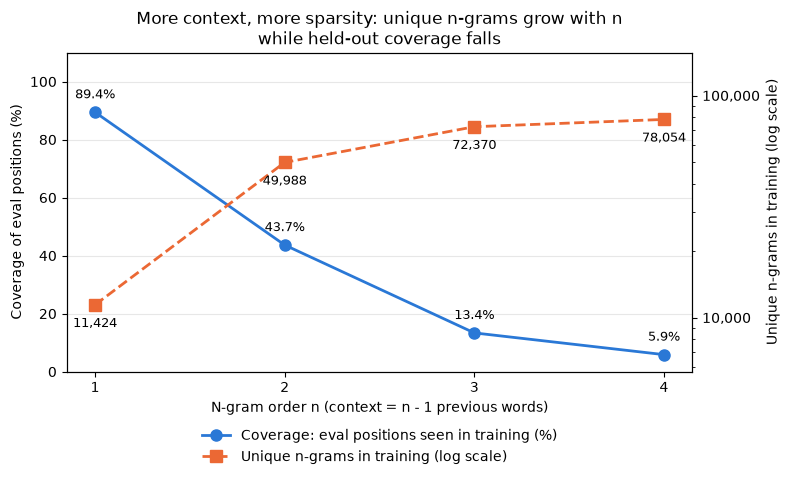

In [12]:
def plot_coverage_vs_sparsity(coverage_results, unique_ngram_counts):
    """Plot n-gram coverage rate and unique n-gram count against n.

    Creates a dual-axis plot: left y-axis for coverage (%), right y-axis
    for unique n-gram count (log scale).

    Args:
        coverage_results     (dict[int, float]): n -> coverage fraction.
        unique_ngram_counts  (dict[int, int]):   n -> unique n-gram count.

    Returns:
        tuple: (fig, ax1) matplotlib figure and primary axes.

    Raises:
        ValueError: If the two dicts are empty or cover different n.
    """
    # Requirements:
    #   - x-axis: n-gram order (1, 2, 3, 4)
    #   - left y-axis: coverage % (multiply fraction by 100)
    #   - right y-axis: unique n-gram count, log scale
    #   - descriptive title that states the trade-off
    #   - both y-axes labeled, x-axis labeled
    #   - legend distinguishing the two lines
    from matplotlib.ticker import NullFormatter, StrMethodFormatter

    orders = sorted(coverage_results)
    if not orders or sorted(unique_ngram_counts) != orders:
        raise ValueError("coverage_results and unique_ngram_counts must be "
                         "non-empty and cover the same n values")
    coverage_pct = [100.0 * coverage_results[n] for n in orders]
    type_counts = [unique_ngram_counts[n] for n in orders]

    fig, ax1 = plt.subplots(figsize=(8, 5))

    # Left axis: share of eval positions whose n-gram occurred in training.
    ax1.plot(orders, coverage_pct, color='#2a78d6', marker='o',
             linewidth=2, markersize=8,
             label='Coverage: eval positions seen in training (%)')
    ax1.set_xlabel('N-gram order n (context = n - 1 previous words)')
    ax1.set_ylabel('Coverage of eval positions (%)')
    ax1.set_xticks(orders)
    ax1.set_ylim(0, 110)
    ax1.grid(axis='y', alpha=0.3)
    for n, pct in zip(orders, coverage_pct):
        ax1.annotate(f'{pct:.1f}%', (n, pct), textcoords='offset points',
                     xytext=(0, 10), ha='center', fontsize=9)

    # Right axis: unique n-gram types in training. Log scale, because each
    # extra word of context multiplies the number of possible n-grams.
    ax2 = ax1.twinx()
    ax2.plot(orders, type_counts, color='#eb6834', marker='s',
             linestyle='--', linewidth=2, markersize=8,
             label='Unique n-grams in training (log scale)')
    ax2.set_yscale('log')
    # Pad the range so the 10,000 and 100,000 ticks both show, and print
    # them as plain numbers instead of 10^4-style labels.
    ax2.set_ylim(min(type_counts) / 2, max(type_counts) * 2)
    ax2.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax2.yaxis.set_minor_formatter(NullFormatter())
    ax2.set_ylabel('Unique n-grams in training (log scale)')
    for n, count in zip(orders, type_counts):
        ax2.annotate(f'{count:,}', (n, count), textcoords='offset points',
                     xytext=(0, -16), ha='center', fontsize=9)

    # One legend for both lines: combine the handles of the two axes.
    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper center',
               bbox_to_anchor=(0.5, -0.14), ncol=1, frameon=False)

    ax1.set_title('More context, more sparsity: unique n-grams grow with n\n'
                  'while held-out coverage falls')
    fig.tight_layout()
    return fig, ax1


unique_counts = {1: unique_unigrams, 2: unique_bigrams,
                 3: unique_trigrams, 4: unique_fourgrams}
fig_coverage, ax_coverage = plot_coverage_vs_sparsity(
    coverage_results, unique_counts)
plt.show()

### 3.4 — Reflection (manually graded, 6 pts)

**Prompt:** Looking at the coverage rates and unique n-gram counts you computed, answer the following in 4–6 sentences.

The Markov assumption limits an n-gram model to a fixed window of context. Choose a specific linguistic phenomenon — something a competent human reader uses when interpreting text — that a bigram model cannot capture due to this window, but that a 5-gram model still could not capture either. Explain the phenomenon, why it falls outside any fixed-window Markov model, and what architectural approach (introduced later in this course) would be needed to handle it properly.

**Your reflection:**

Subject–verb agreement across a relative clause needs more context than any fixed window offers: in "The **reports** that the committee submitted to the board last quarter **were** rejected", the verb's number depends on *reports*, with nine words in between. A 5-gram sees only "the board last quarter", whose singular nouns favour the wrong form *was*, and a bigram sees only *quarter*, while a human reader simply carries the plural subject across the clause. No fixed n is enough: the Markov assumption (J&M, *N-gram Language Models*) discards everything beyond the previous n−1 words, and a relative clause can always be made longer than the window. Raising n is impractical anyway: held-out coverage already falls to 5.9% at n = 4, and the 78,054 distinct training 4-grams almost match the 83,493 training tokens, so most 4-grams occur only once. The fix is a model that is not limited to the previous n−1 words, such as an LSTM, whose gated cell state can carry the subject's number through the clause (J&M, *RNNs and LSTMs*). A transformer goes further, since self-attention lets the verb look straight back at *reports*, and in both architectures learned embeddings let the agreement pattern generalize to word pairs never seen together (J&M, *Transformers and Pretraining*).

---

## Part 4 — Smoothing: Laplace and Kneser-Ney (21 points)

MLE assigns zero probability to any n-gram not seen in training. This makes MLE models brittle: a single unseen bigram sends an entire sentence probability to zero. Smoothing redistributes probability mass from seen n-grams to unseen ones.

### Laplace (add-one) smoothing

Add 1 to every n-gram count before normalizing:

$$P_{Lap}(w_n \mid w_{n-1}) = \frac{C(w_{n-1},\, w_n) + 1}{C(w_{n-1}) + V}$$

Simple and interpretable, but it can over-redistribute probability mass — in practice it assigns too much probability to unseen bigrams when V is large.

### Kneser-Ney smoothing

Kneser-Ney addresses a key shortcoming of Laplace: it ignores *how versatile* a word is. Consider the word "Francisco" — it appears frequently in training, but almost exclusively after "San". Laplace would assign a high unigram backoff probability to "Francisco" based on its raw frequency. Kneser-Ney instead uses a **continuation probability** — how many distinct left contexts a word appears in — as the backoff unigram:

$$P_{cont}(w) = \frac{|\{v :\, C(v,\, w) > 0\}|}{\sum_{w'} |\{v :\, C(v,\, w') > 0\}|}$$

The full bigram KN formula is:

$$P_{KN}(w_n \mid w_{n-1}) = \frac{\max(C(w_{n-1},\, w_n) - d,\; 0)}{C(w_{n-1})} + \lambda(w_{n-1}) \cdot P_{cont}(w_n)$$

where $d$ is the discount (typically 0.75) and $\lambda(w_{n-1})$ is a normalisation constant:

$$\lambda(w_{n-1}) = \frac{d}{C(w_{n-1})} \cdot |\{w :\, C(w_{n-1},\, w) > 0\}|$$

**Important:** KN assigns zero probability to words that never appeared as the *right side* of any bigram in training (i.e., words that are truly absent from the continuation vocabulary). This is correct behaviour — these words are genuinely OOV in a KN model. The tests will only check KN on words that appear in training.

### 4.1 — Laplace smoothing

**What the code in Part 4 does.** `laplace_prob` adds one to every bigram count and V to every context count, so every unseen bigram after w₁ gets the same probability 1 / (C(w₁) + V) (J&M, *N-gram Language Models*, §3.6); V = `len(unigram_counts)` counts `</s>` but not `<s>`, which is never predicted. The Kneser-Ney model is **interpolated Kneser-Ney** (J&M, *Kneser-Ney Smoothing*, Eq. C.7): absolute discounting subtracts d = 0.75 from every seen bigram count, and λ(w₁) gives exactly that mass back through the continuation probability P_cont(w₂), which favours words that follow many different words over words that are merely frequent. Both terms are always added, which makes it interpolation rather than backoff. Two edge cases are explicit: a w₂ with no continuation count gets P = 0 and is skipped in perplexity, while Laplace scores those positions, so the two perplexities cover different tokens; and an unseen previous word (C(w₁) = 0) falls back to P_cont(w₂) instead of dividing by zero.

In [13]:
def laplace_prob(ngram, ngram_counts, context_counts, V):
    """Compute Laplace (add-one) smoothed conditional probability.

    P_Lap(w_n | context) = (C(ngram) + 1) / (C(context) + V)

    Args:
        ngram          (tuple[str]): The full n-gram.
        ngram_counts   (Counter):   N-gram counts.
        context_counts (Counter):   (N-1)-gram counts.
        V              (int):       Vocabulary size: the number of
                                    predictable types,
                                    len(unigram_counts) (includes
                                    '</s>' but not '<s>').

    Returns:
        float: Smoothed conditional probability > 0.

    Raises:
        ValueError: If V <= 0 or ngram is empty.
    """
    if V <= 0:
        raise ValueError(f"Vocabulary size V must be positive, got {V!r}")
    ngram = tuple(ngram)
    if not ngram:
        raise ValueError("ngram must contain at least one word")
    context = ngram[:-1]
    # For n = 1 the context is empty and C(context) is the token count N.
    context_count = (context_counts.get(context, 0) if context
                     else sum(context_counts.values()))
    # Add 1 to the n-gram count and V to the context count, so the V
    # possible next words still share a total probability of 1.
    return (ngram_counts.get(ngram, 0) + 1) / (context_count + V)


def laplace_perplexity(sentences, n, ngram_counts, context_counts, V):
    """Compute perplexity using Laplace-smoothed probabilities.

    No zeros are skipped — Laplace guarantees non-zero probability for
    all n-grams.
    Uses log base 2.

    Args:
        sentences      (list[list[str]]): Test sentences (no markers).
        n              (int):             N-gram order.
        ngram_counts   (Counter):         N-gram counts.
        context_counts (Counter):         (N-1)-gram counts.
        V              (int):             Vocabulary size.

    Returns:
        float: Perplexity over every predicted position (each word and
               '</s>'); float('inf') if sentences is empty.

    Raises:
        ValueError: If V <= 0 or n is not an integer >= 1.
    """
    # Validate V and n up front so an empty sentence list still fails fast.
    if V <= 0:
        raise ValueError(f"Vocabulary size V must be positive, got {V!r}")
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError(f"n-gram order n must be an integer >= 1, got {n!r}")
    log2_sum, n_scored = 0.0, 0
    for sentence in sentences:
        padded = add_sentence_markers(sentence, n)
        # Same positions as Part 2: every word and '</s>', never '<s>'.
        for i in range(n - 1, len(padded)):
            ngram = tuple(padded[i - n + 1:i + 1])
            # Laplace never returns 0, so every position is scored.
            prob = laplace_prob(ngram, ngram_counts, context_counts, V)
            log2_sum += math.log2(prob)
            n_scored += 1
    if n_scored == 0:
        return float('inf')
    return 2.0 ** (-log2_sum / n_scored)


# Named output variables
p_laplace_seen = laplace_prob(
    ('<s>', 'the'), bigram_counts, bigram_context_counts, V)
p_laplace_unseen = laplace_prob(('the', 'zzzneverseenword'),
                                 bigram_counts, bigram_context_counts, V)

ppl_laplace = laplace_perplexity(
    EVAL_SENTS, 2, bigram_counts, bigram_context_counts, V)

print(f"Laplace P('the'           | '<s>') = {p_laplace_seen:.6f}")
print(f"Laplace P('zzzneverseenword' | 'the') = {p_laplace_unseen:.8f}")
print(f"\nLaplace bigram perplexity: {ppl_laplace:.2f}")
print(f"MLE    bigram perplexity:  {ppl_bigram:.2f}  (zeros skipped)")
print()
print("Laplace perplexity covers ALL token positions (no skipping).")

Laplace P('the'           | '<s>') = 0.040603
Laplace P('zzzneverseenword' | 'the') = 0.00006062

Laplace bigram perplexity: 3670.70
MLE    bigram perplexity:  28.66  (zeros skipped)

Laplace perplexity covers ALL token positions (no skipping).


### 4.2 — Precompute Kneser-Ney statistics

Before implementing the KN probability function, precompute the continuation counts and follower sets. Doing this once up front makes the probability function efficient.

In [14]:
def build_kn_stats(bigram_counts):
    """Precompute Kneser-Ney continuation counts and follower sets.

    Args:
        bigram_counts (Counter): Bigram counts from training.

    Returns:
        tuple:
            continuation_counts (Counter): Maps each word w to the number of
                distinct words that precede it: |{v : C(v,w) > 0}|.
            total_continuation  (int):     Sum of all continuation counts.
            followers           (dict):    Maps each word w1 to a set of words
                that follow it: {w2 : C(w1,w2) > 0}.

    Raises:
        ValueError: If a key of bigram_counts is not a 2-tuple.
    """
    continuation_counts = Counter()
    followers = defaultdict(set)
    for bigram, count in bigram_counts.items():
        if len(bigram) != 2:
            raise ValueError(f"expected bigram keys, got {bigram!r}")
        if count <= 0:
            continue  # a zero entry is not an observed bigram type
        w1, w2 = bigram
        # Each distinct bigram type (w1, w2) adds one left context for w2.
        continuation_counts[w2] += 1
        followers[w1].add(w2)
    # Denominator of P_cont: the number of distinct bigram types.
    total_continuation = sum(continuation_counts.values())
    # Plain dict, so looking up an unseen w1 cannot insert an empty set.
    return continuation_counts, total_continuation, dict(followers)


continuation_counts, total_continuation, followers = build_kn_stats(
    bigram_counts)

print(f"Total continuation count: {total_continuation:,}")
print(f"\nTop 10 words by continuation count (most versatile right contexts):")
for word, count in continuation_counts.most_common(10):
    print(f"  {word:15s}  {count:4d}")

Total continuation count: 49,988

Top 10 words by continuation count (most versatile right contexts):
  ,                2440
  .                1754
  of               1139
  and              1088
  in                919
  to                878
  the               713
  for               513
  ''                473
  a                 423


### 4.3 — Kneser-Ney probability

In [15]:
KN_DISCOUNT = 0.75   # standard value; do not change

def kn_bigram_prob(w1, w2, bigram_counts, bigram_context_counts,
                   continuation_counts, total_continuation,
                   followers, discount=KN_DISCOUNT):
    """Compute Kneser-Ney smoothed bigram probability P_KN(w2 | w1).

    Formula (interpolated Kneser-Ney, J&M Eq. C.7):
        P_KN(w2|w1) = max(C(w1,w2) - d, 0) / C(w1)
                    + lambda(w1) * P_cont(w2)

        lambda(w1)   = d / C(w1) * |{w : C(w1,w) > 0}|
        P_cont(w2)   = continuation_counts[w2] / total_continuation

    Returns 0.0 if w2 has no continuation count (never appeared as the
    right side of any training bigram — true OOV for KN).

    If w1 never occurred as a context in training (C(w1) = 0), both
    terms would divide by zero. The function then gives all the mass
    to the continuation distribution and returns P_cont(w2), which is
    the same as setting lambda(w1) = 1. This happens at every position
    right after an out-of-vocabulary word.

    Args:
        w1                   (str):     The previous word (context).
        w2                   (str):     The word being predicted.
        bigram_counts        (Counter): Bigram counts.
        bigram_context_counts (Counter): Bigram context (unigram) counts.
        continuation_counts  (Counter): From build_kn_stats().
        total_continuation   (int):     From build_kn_stats().
        followers            (dict):    From build_kn_stats().
        discount             (float):   Absolute discount value.

    Returns:
        float: KN-smoothed probability >= 0.

    Raises:
        ValueError: If discount is outside [0, 1].
    """
    # d <= 1 keeps every seen count C(w1, w2) >= 1 non-negative after
    # discounting, so lambda returns exactly the mass that was removed.
    if not 0.0 <= discount <= 1.0:
        raise ValueError(f"discount must be in [0, 1], got {discount!r}")

    # Continuation probability: in how many distinct contexts did w2 appear?
    continuation = continuation_counts.get(w2, 0)
    if continuation == 0 or total_continuation <= 0:
        return 0.0  # w2 never followed any word in training (KN OOV)
    p_continuation = continuation / total_continuation

    context_count = bigram_context_counts.get((w1,), 0)
    if context_count == 0:
        # Unseen previous word: no bigram evidence, and both terms would
        # divide by zero. Use the continuation distribution alone.
        return p_continuation

    # First term: absolute discounting of the observed bigram count.
    discounted = (max(bigram_counts.get((w1, w2), 0) - discount, 0.0)
                  / context_count)
    # lambda(w1): d was subtracted once per distinct follower of w1, so this
    # weight hands back exactly the mass the first term removed.
    interpolation_weight = (discount * len(followers.get(w1, ()))
                            / context_count)
    return discounted + interpolation_weight * p_continuation


def kn_perplexity(sentences, bigram_counts, bigram_context_counts,
                  continuation_counts, total_continuation,
                  followers, discount=KN_DISCOUNT):
    """Compute perplexity using Kneser-Ney smoothed bigram probabilities.

    Skip positions where P_KN = 0 (true OOV — word never appeared as
    the right side of any training bigram). Uses log base 2.

    Args:
        sentences             (list[list[str]]): Test sentences (no markers).
        bigram_counts         (Counter): Bigram counts.
        bigram_context_counts (Counter): Bigram context (unigram) counts.
        continuation_counts   (Counter): From build_kn_stats().
        total_continuation    (int):     From build_kn_stats().
        followers             (dict):    From build_kn_stats().
        discount              (float):   Absolute discount value.

    Returns:
        float: Perplexity over the positions with P_KN > 0; float('inf')
               if no position could be scored.

    Raises:
        ValueError: If discount is outside [0, 1].
    """
    # Validate d up front so an empty sentence list still fails fast.
    if not 0.0 <= discount <= 1.0:
        raise ValueError(f"discount must be in [0, 1], got {discount!r}")
    log2_sum, n_scored = 0.0, 0
    for sentence in sentences:
        padded = add_sentence_markers(sentence, 2)
        # Positions 1 .. end: every word and '</s>', each predicted from the
        # token before it ('<s>' is context only).
        for i in range(1, len(padded)):
            prob = kn_bigram_prob(padded[i - 1], padded[i], bigram_counts,
                                  bigram_context_counts, continuation_counts,
                                  total_continuation, followers, discount)
            # P_KN = 0 only for a w2 with no continuation count (KN OOV):
            # skip it, so N counts only the tokens KN can score.
            if prob == 0.0:
                continue
            log2_sum += math.log2(prob)
            n_scored += 1
    if n_scored == 0:
        return float('inf')
    return 2.0 ** (-log2_sum / n_scored)


# Named output variables — test on bigrams where w2 IS in the training vocab
# ('president','said') - 'said' appears in many contexts
p_kn_seen = kn_bigram_prob(
    'the', 'president', bigram_counts, bigram_context_counts,
    continuation_counts, total_continuation, followers)
# unseen bigram but w2 ('market') has appeared in training
p_kn_unseen_bigram = kn_bigram_prob(
    'president', 'market', bigram_counts, bigram_context_counts,
    continuation_counts, total_continuation, followers)

ppl_kn = kn_perplexity(EVAL_SENTS, bigram_counts, bigram_context_counts,
                        continuation_counts, total_continuation, followers)

print(f"KN P('president' | 'the')       = {p_kn_seen:.6f}  (seen bigram)")
print(f"KN P('market'  | 'president')   = {p_kn_unseen_bigram:.6f}  "
      f"(unseen bigram, w2 in vocab)")
print(f"\nKN bigram perplexity:      {ppl_kn:.2f}")
print(f"Laplace bigram perplexity: {ppl_laplace:.2f}")
print(f"MLE bigram perplexity:     {ppl_bigram:.2f}  (zeros skipped)")

KN P('president' | 'the')       = 0.006962  (seen bigram)
KN P('market'  | 'president')   = 0.000061  (unseen bigram, w2 in vocab)

KN bigram perplexity:      315.13
Laplace bigram perplexity: 3670.70
MLE bigram perplexity:     28.66  (zeros skipped)


### 4.4 — Summary comparison table

In [16]:
# [RUN] — comparison summary. Do not modify.

print("=" * 55)
print(f"{'Model':<30s} {'Perplexity':>10s}  {'Coverage'}")
print("=" * 55)
mle_zeros, mle_total = count_zero_ngrams(
    EVAL_SENTS, 2, bigram_counts, bigram_context_counts)
mle_cov = 1 - mle_zeros / mle_total
print(f"{'Bigram MLE (skip zeros)':<30s} {ppl_bigram:>10.2f}  "
      f"{mle_cov:.1%} covered")
print(f"{'Bigram Laplace':<30s} {ppl_laplace:>10.2f}  100% covered")
print(f"{'Bigram Kneser-Ney':<30s} {ppl_kn:>10.2f}  ~100% covered*")
print("=" * 55)
print("* KN assigns 0 only to true OOV words (never seen as w2 in training).")

Model                          Perplexity  Coverage
Bigram MLE (skip zeros)             28.66  43.7% covered
Bigram Laplace                    3670.70  100% covered
Bigram Kneser-Ney                  315.13  ~100% covered*
* KN assigns 0 only to true OOV words (never seen as w2 in training).


*Note:* the KN row's "~100% covered*" above is approximate. KN skips every position whose w₂ never appeared as the right side of a training bigram; Part 5 counts those positions exactly and compares Laplace and KN on identical tokens.

### 4.5 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** Kneser-Ney typically achieves lower perplexity than Laplace on the Brown corpus. Explain the specific mechanism that gives it an advantage. Focus on what happens to high-frequency words that appear in only a few distinct contexts — use "Francisco" / "San Francisco" as a concrete example in your explanation, even if the word doesn't appear in the Brown news corpus.

**Question B:** Both Laplace and Kneser-Ney are bigram smoothing methods. When would you consider using a smoothed trigram model instead of a smoothed bigram, and what additional engineering challenges would that introduce?

**Your reflection:**

**A.** Most of KN's lead over Laplace comes from interpolated absolute discounting (J&M, *Kneser-Ney Smoothing*, Eq. C.1): subtracting d = 0.75 instead of adding one to every type keeps P(francisco | san) at 0.6974, where Laplace gives 0.0013. The freed mass then goes to a unigram distribution rather than uniformly over all types, and on identical tokens in 5.5 below these two changes take perplexity from 3168.98 to 325.24, while continuation probability only lowers it to 315.13. Continuation probability P_cont(w) is the number of distinct words that precede w, as a share of all bigram types, so *francisco*, seen 14 times but only after *san*, gets 2.00e-05 against a unigram probability of 1.68e-04 (Table 5.4 below). After *the*, where none of these bigrams occurred in training, KN gives the one-context *york* 6.74e-06 but the similarly frequent, versatile *through* 2.36e-04, whereas Eq. C.1's unigram term would rate them almost equally.

**B.** A smoothed trigram pays off only when the corpus is large enough for most two-word contexts to recur; here only 13.4% of held-out trigrams were seen, so at the other 86.6% of positions an interpolated KN trigram would take all its probability from the λ-weighted bigram term. Moving up also means recursive KN with continuation counts at each lower order (J&M, *Kneser-Ney Smoothing*), discounts (ideally modified KN's d₁, d₂, d₃₊) chosen on a held-out set rather than the test set, and far more n-grams to store.

---

## Part 5 — Matched-token comparison and Kneser-Ney diagnostics (extension)

The three bigram perplexities in 4.4 are averages over different tokens. MLE skips every position whose bigram never occurred in training, Kneser-Ney skips every position whose w₂ never appeared as the right side of a training bigram, and Laplace scores every position. J&M (*N-gram Language Models*, §3.3) compare perplexities only between models with identical vocabularies, and the same logic applies to the tokens a perplexity is averaged over. Sections 5.1–5.3 make the comparison fair, and 5.4–5.6 explain the results:

- **5.1** counts exactly how many positions each model scored and skipped, and lists the w₂ words that KN cannot score.
- **5.2** checks that P_Lap(· | w₁) and P_KN(· | w₁) each sum to 1 over the same V predictable types.
- **5.3** scores Laplace and KN on only the positions KN can score, then all three models on only the positions MLE can score.
- **5.4** sets word frequency against continuation count for *francisco*, *york* and *through*.
- **5.5** turns Laplace into KN one change at a time, to show which change does the work.
- **5.6** lists the unseen n-grams behind the three −∞ log probabilities in 1.5.

All models are the ones trained above on the news `train_sents`. Nothing is retrained, and no graded variable is reassigned: every new name starts with `ext_`.

In [17]:
# Part 5 helpers. The three bigram models trained above (news train_sents)
# are wrapped as functions bigram -> P(w2 | w1) for ext_evaluate().

import string  # punctuation characters, used in 5.6 and 6.1


def ext_mle_bigram(bigram):
    """Return the MLE bigram probability from Part 1.

    Args:
        bigram (tuple[str, str]): (w1, w2).

    Returns:
        float: P_MLE(w2 | w1); 0.0 for an unseen bigram.
    """
    return mle_prob(bigram, bigram_counts, bigram_context_counts)


def ext_laplace_bigram(bigram):
    """Return the Laplace bigram probability from Part 4.1.

    Args:
        bigram (tuple[str, str]): (w1, w2).

    Returns:
        float: P_Lap(w2 | w1), always > 0.
    """
    return laplace_prob(bigram, bigram_counts, bigram_context_counts, V)


def ext_kn_bigram(bigram):
    """Return the interpolated Kneser-Ney bigram probability from Part 4.3.

    Args:
        bigram (tuple[str, str]): (w1, w2).

    Returns:
        float: P_KN(w2 | w1); 0.0 if w2 has no continuation count.
    """
    w1, w2 = bigram
    return kn_bigram_prob(w1, w2, bigram_counts, bigram_context_counts,
                          continuation_counts, total_continuation, followers)


def ext_kn_can_score(bigram):
    """Check whether Kneser-Ney gives a position a non-zero probability.

    Args:
        bigram (tuple[str, str]): (w1, w2).

    Returns:
        bool: True if P_KN(w2 | w1) > 0.
    """
    return ext_kn_bigram(bigram) > 0.0


def ext_mle_can_score(bigram):
    """Check whether MLE gives a position a non-zero probability.

    Args:
        bigram (tuple[str, str]): (w1, w2).

    Returns:
        bool: True if the bigram occurred in training (P_MLE > 0).
    """
    return ext_mle_bigram(bigram) > 0.0


def ext_restrict(prob_fn, keep_fn):
    """Limit a bigram model to the positions that keep_fn accepts.

    Args:
        prob_fn (Callable[[tuple[str, str]], float]): Model to score with.
        keep_fn (Callable[[tuple[str, str]], bool]):  True for a position
                that should be scored.

    Returns:
        Callable[[tuple[str, str]], float]: prob_fn where keep_fn is True
            and 0.0 elsewhere, so ext_evaluate() counts the position as
            skipped.
    """
    return lambda bigram: prob_fn(bigram) if keep_fn(bigram) else 0.0


def ext_bigram_positions(sentences):
    """List the bigram at every predicted position of the sentences.

    Args:
        sentences (list[list[str]]): Sentences (no markers).

    Returns:
        list[tuple[str, str]]: One (w1, w2) per word and per '</s>'.
    """
    positions = []
    for sentence in sentences:
        padded = add_sentence_markers(sentence, 2)
        # (padded[i-1], padded[i]) for i = 1 .. end; '<s>' is never predicted.
        positions.extend(zip(padded[:-1], padded[1:]))
    return positions


def ext_evaluate(sentences, prob_fn):
    """Score sentences with a bigram model and count what it covered.

    Positions where prob_fn returns 0 are skipped (log2 0 = -inf) and
    counted separately, as in compute_perplexity() with skip_zeros=True.

    Args:
        sentences (list[list[str]]): Test sentences (no markers).
        prob_fn   (Callable[[tuple[str, str]], float]): Bigram model.

    Returns:
        dict: 'ppl' (perplexity over the scored positions) and the
            'scored', 'skipped' and 'total' position counts.
    """
    log2_sum, n_scored, n_skipped = 0.0, 0, 0
    for bigram in ext_bigram_positions(sentences):
        prob = prob_fn(bigram)
        if prob > 0.0:
            log2_sum += math.log2(prob)
            n_scored += 1
        else:
            n_skipped += 1
    # PP = 2 ** (cross-entropy in bits per scored token).
    ppl = 2.0 ** (-log2_sum / n_scored) if n_scored else float('inf')
    return {'ppl': ppl, 'scored': n_scored, 'skipped': n_skipped,
            'total': n_scored + n_skipped}


def ext_print_table(title, results):
    """Print perplexity and position counts for several models.

    Args:
        title   (str):             Heading printed above the table.
        results (dict[str, dict]): Model label -> ext_evaluate() output.
    """
    print(title)
    print(f"{'Model':<26s} {'Perplexity':>10s} {'Scored':>7s} "
          f"{'Skipped':>8s} {'Total':>6s} {'Scored %':>9s}")
    for label, res in results.items():
        share = res['scored'] / res['total'] if res['total'] else 0.0
        print(f"{label:<26s} {res['ppl']:>10.2f} {res['scored']:>7,} "
              f"{res['skipped']:>8,} {res['total']:>6,} {share:>9.1%}")
    print()


ext_models = {'Bigram MLE (skip zeros)': ext_mle_bigram,
              'Bigram Laplace': ext_laplace_bigram,
              'Bigram Kneser-Ney': ext_kn_bigram}
print("Part 5 helpers defined.")

Part 5 helpers defined.


### 5.1 — Exact coverage of the three bigram models

The perplexities are recomputed with the shared scorer and checked against the graded values, so the counts below describe exactly the numbers in 4.4.

In [18]:
ext_full = {label: ext_evaluate(EVAL_SENTS, fn)
            for label, fn in ext_models.items()}
ext_print_table("Bigram models on EVAL_SENTS (each model skips its own "
                "zeros):", ext_full)

# The recomputed perplexities must equal the graded values from Parts 2 and 4.
assert math.isclose(ext_full['Bigram MLE (skip zeros)']['ppl'], ppl_bigram)
assert math.isclose(ext_full['Bigram Laplace']['ppl'], ppl_laplace)
assert math.isclose(ext_full['Bigram Kneser-Ney']['ppl'], ppl_kn)

# Which w2 does KN skip, and are they all absent from the training data?
ext_eval_bigrams = ext_bigram_positions(EVAL_SENTS)
ext_kn_skipped = Counter(bigram[1] for bigram in ext_eval_bigrams
                         if not ext_kn_can_score(bigram))
ext_skipped_all_oov = all((word,) not in unigram_counts
                          for word in ext_kn_skipped)
print(f"KN skipped {sum(ext_kn_skipped.values()):,} of "
      f"{len(ext_eval_bigrams):,} positions ({len(ext_kn_skipped):,} "
      f"distinct w2 types).")
print(f"Every skipped w2 is absent from the training vocabulary: "
      f"{ext_skipped_all_oov}")
print("Most frequent skipped w2 (count):")
print("  " + ", ".join(f"{word} ({count})"
                       for word, count in ext_kn_skipped.most_common(25)))

# Positions right after an unseen word use the C(w1) = 0 fallback P_cont(w2).
ext_fallback_positions = sum(
    1 for w1, w2 in ext_eval_bigrams
    if bigram_context_counts.get((w1,), 0) == 0
    and continuation_counts.get(w2, 0) > 0)
print(f"\nPositions scored with the C(w1) = 0 fallback P_cont(w2): "
      f"{ext_fallback_positions:,}")

Bigram models on EVAL_SENTS (each model skips its own zeros):
Model                      Perplexity  Scored  Skipped  Total  Scored %
Bigram MLE (skip zeros)         28.66   2,274    2,935  5,209     43.7%
Bigram Laplace                3670.70   5,209        0  5,209    100.0%
Bigram Kneser-Ney              315.13   4,659      550  5,209     89.4%

KN skipped 550 of 5,209 positions (467 distinct w2 types).
Every skipped w2 is absent from the training vocabulary: True
Most frequent skipped w2 (count):
  anti-trust (21), colmer (6), president-elect (4), electrical (3), monopoly (3), commodity (3), monopolies (3), employers (3), herter (3), fronts (3), congo (3), humphrey (3), holes (3), argue (2), allegedly (2), aircraft (2), abuses (2), rationale (2), heavy-electrical-goods (2), marginal (2), protection (2), implicit (2), theory (2), penalties (2), rational (2)

Positions scored with the C(w1) = 0 fallback P_cont(w2): 498


### 5.2 — One vocabulary, proper distributions

For each context w₁ below, P(w | w₁) is summed over all V predictable types (the training words plus `</s>`). Both smoothed models should give exactly 1, including for the C(w₁) = 1 context and for an unseen w₁, where KN falls back to P_cont.

In [19]:
ext_vocab = [ngram[0] for ngram in unigram_counts]   # V types, incl. '</s>'
print(f"V = {len(ext_vocab):,} predictable types; '<s>' among them: "
      f"{'<s>' in set(ext_vocab)}")
print(f"KN continuation vocabulary == Laplace vocabulary: "
      f"{set(continuation_counts) == set(ext_vocab)}\n")


def ext_distribution_mass(w1, vocab):
    """Sum the Laplace and KN probabilities of every next word after w1.

    Args:
        w1    (str):       Context word.
        vocab (list[str]): The types the models can predict.

    Returns:
        tuple[float, float]: (sum of P_Lap(w | w1), sum of P_KN(w | w1)).
    """
    laplace_mass = math.fsum(ext_laplace_bigram((w1, w)) for w in vocab)
    kn_mass = math.fsum(ext_kn_bigram((w1, w)) for w in vocab)
    return laplace_mass, kn_mass


# A context seen exactly once (alphabetically first, for reproducibility).
ext_rare_context = min(context[0]
                       for context, count in bigram_context_counts.items()
                       if count == 1)
ext_mass_check = {w1: ext_distribution_mass(w1, ext_vocab)
                  for w1 in ['<s>', 'the', 'president', ext_rare_context,
                             'zzzneverseenword']}

print(f"{'Context w1':<18s} {'C(w1)':>7s} {'sum P_Lap':>16s} "
      f"{'sum P_KN':>16s}")
for ext_w1, (ext_lap_mass, ext_kn_mass) in ext_mass_check.items():
    print(f"{ext_w1:<18s} {bigram_context_counts.get((ext_w1,), 0):>7,} "
          f"{ext_lap_mass:>16.12f} {ext_kn_mass:>16.12f}")
    assert math.isclose(ext_lap_mass, 1.0, abs_tol=1e-9)
    assert math.isclose(ext_kn_mass, 1.0, abs_tol=1e-9)

V = 11,424 predictable types; '<s>' among them: False
KN continuation vocabulary == Laplace vocabulary: True

Context w1           C(w1)        sum P_Lap         sum P_KN
<s>                  3,698   1.000000000000   1.000000000000
the                  5,072   1.000000000000   1.000000000000
president              114   1.000000000000   1.000000000000
$1,000,000,000           1   1.000000000000   1.000000000000
zzzneverseenword         0   1.000000000000   1.000000000000


### 5.3 — Perplexity on identical tokens

Table A scores Laplace on only the positions KN can score, so Laplace and KN average over the same tokens. Table B restricts all three models to the positions MLE can score (bigrams seen in training).

In [20]:
ext_matched_kn = {
    'Bigram Laplace': ext_evaluate(
        EVAL_SENTS, ext_restrict(ext_laplace_bigram, ext_kn_can_score)),
    'Bigram Kneser-Ney': ext_evaluate(EVAL_SENTS, ext_kn_bigram),
}
ext_print_table("A. Positions KN can score (P_KN > 0):", ext_matched_kn)

ext_matched_seen = {label: ext_evaluate(EVAL_SENTS,
                                        ext_restrict(fn, ext_mle_can_score))
                    for label, fn in ext_models.items()}
ext_print_table("B. Positions MLE can score (bigram seen in training):",
                ext_matched_seen)

# Each table must compare its models on the same number of positions.
assert len({res['scored'] for res in ext_matched_kn.values()}) == 1
assert len({res['scored'] for res in ext_matched_seen.values()}) == 1

ext_lap_all = ext_full['Bigram Laplace']['ppl']
ext_lap_matched = ext_matched_kn['Bigram Laplace']['ppl']
print(f"Laplace PP, all positions -> KN positions only: {ext_lap_all:.2f} -> "
      f"{ext_lap_matched:.2f}")
print(f"KN / Laplace perplexity ratio on identical tokens: "
      f"{ext_matched_kn['Bigram Kneser-Ney']['ppl'] / ext_lap_matched:.3f}")

A. Positions KN can score (P_KN > 0):
Model                      Perplexity  Scored  Skipped  Total  Scored %
Bigram Laplace                3168.98   4,659      550  5,209     89.4%
Bigram Kneser-Ney              315.13   4,659      550  5,209     89.4%

B. Positions MLE can score (bigram seen in training):
Model                      Perplexity  Scored  Skipped  Total  Scored %
Bigram MLE (skip zeros)         28.66   2,274    2,935  5,209     43.7%
Bigram Laplace                 795.82   2,274    2,935  5,209     43.7%
Bigram Kneser-Ney               37.74   2,274    2,935  5,209     43.7%

Laplace PP, all positions -> KN positions only: 3670.70 -> 3168.98
KN / Laplace perplexity ratio on identical tokens: 0.099


### 5.4 — Frequency vs. continuation count

The *Francisco* example from reflection 4.5, measured in this training set. *francisco* and *york* each follow only one word in training (*san* and *new*), while *through*, about as frequent as *york*, follows many different words. None of the three bigrams after *the* occurred in training, so KN gives each word λ(the)·P_cont(w), and Laplace gives each the same 1 / (C(the) + V). The last column shows what interpolated absolute discounting (J&M Eq. C.1) would assign using the ordinary unigram distribution P(w) instead of P_cont.

In [21]:
ext_context = 'the'
ext_context_count = bigram_context_counts[(ext_context,)]
ext_lambda = KN_DISCOUNT * len(followers[ext_context]) / ext_context_count
print(f"Context w1 = '{ext_context}': C(w1) = {ext_context_count:,}, "
      f"{len(followers[ext_context]):,} distinct followers, "
      f"lambda(w1) = {ext_lambda:.4f}\n")
print(f"{'w':<10s} {'C(w)':>5s} {'left ctx':>8s} {'P_unigram':>10s} "
      f"{'P_cont':>9s} {'P_KN(w|the)':>12s} {'P_Lap(w|the)':>13s} "
      f"{'lambda*P_uni':>13s}")
for ext_w in ['francisco', 'york', 'through']:
    # Every bigram here is unseen, so KN reduces to lambda(w1) * P_cont(w).
    assert bigram_counts.get((ext_context, ext_w), 0) == 0
    ext_p_cont = continuation_counts[ext_w] / total_continuation
    ext_p_uni = unigram_counts[(ext_w,)] / N
    ext_p_kn = ext_kn_bigram((ext_context, ext_w))
    assert math.isclose(ext_p_kn, ext_lambda * ext_p_cont)
    print(f"{ext_w:<10s} {unigram_counts[(ext_w,)]:>5,} "
          f"{continuation_counts[ext_w]:>8,} {ext_p_uni:>10.2e} "
          f"{ext_p_cont:>9.2e} {ext_p_kn:>12.2e} "
          f"{ext_laplace_bigram((ext_context, ext_w)):>13.2e} "
          f"{ext_lambda * ext_p_uni:>13.2e}")

print("\nSeen bigrams, MLE / KN / Laplace:")
for ext_bigram in [('san', 'francisco'), ('new', 'york')]:
    print(f"  P({ext_bigram[1]} | {ext_bigram[0]}): "
          f"{ext_mle_bigram(ext_bigram):.4f} / "
          f"{ext_kn_bigram(ext_bigram):.4f} / "
          f"{ext_laplace_bigram(ext_bigram):.4f}")

Context w1 = 'the': C(w1) = 5,072, 2,277 distinct followers, lambda(w1) = 0.3367

w           C(w) left ctx  P_unigram    P_cont  P_KN(w|the)  P_Lap(w|the)  lambda*P_uni
francisco     14        1   1.68e-04  2.00e-05     6.74e-06      6.06e-05      5.65e-05
york          38        1   4.55e-04  2.00e-05     6.74e-06      6.06e-05      1.53e-04
through       36       35   4.31e-04  7.00e-04     2.36e-04      6.06e-05      1.45e-04

Seen bigrams, MLE / KN / Laplace:
  P(francisco | san): 0.7368 / 0.6974 / 0.0013
  P(york | new): 0.2011 / 0.1971 / 0.0034


### 5.5 — Which part of Kneser-Ney does the work?

Laplace is MLE interpolated with a uniform distribution: (C(w₁w₂) + 1) / (C(w₁) + V) = (1 − λ)·C(w₁w₂) / C(w₁) + λ·(1/V), with λ = V / (C(w₁) + V), and the cell checks this identity on one bigram. Interpolated KN differs from Laplace in three ways: (1) it subtracts a fixed d from each seen count instead of adding one to every type; (2) it hands the freed mass to a unigram distribution instead of spreading it uniformly over the V types; and (3) it replaces unigram frequency with the continuation probability. The chain below changes one of these at a time: (i) Laplace; (ii) interpolated absolute discounting with the uniform 1/V; (iii) the same with the ordinary unigram distribution P(w) = C(w) / N, which is J&M Eq. C.1 (*Kneser-Ney Smoothing*); and (iv) KN, Eq. C.7. Models (ii) and (iii) use KN's d = 0.75 and λ(w₁), use their lower-order term alone when C(w₁) = 0, and are checked to sum to 1 over the V types. All four are scored on the positions KN can score; the cross-entropy decomposition depends on the order in which the changes are made.

In [22]:
def ext_absdisc_uniform_bigram(bigram):
    """Return interpolated absolute discounting with a uniform lower order.

        P(w2 | w1) = max(C(w1 w2) - d, 0) / C(w1) + lambda(w1) * (1 / V)

    d = KN_DISCOUNT and lambda(w1) = d / C(w1) * |{w : C(w1 w) > 0}|, as in
    KN; an unseen w1 (C(w1) = 0) gets the uniform 1 / V alone.

    Args:
        bigram (tuple[str, str]): (w1, w2).

    Returns:
        float: The smoothed probability of w2 after w1.
    """
    w1, w2 = bigram
    p_uniform = 1.0 / V
    context_count = bigram_context_counts.get((w1,), 0)
    if context_count == 0:
        return p_uniform
    discounted = (max(bigram_counts.get((w1, w2), 0) - KN_DISCOUNT, 0.0)
                  / context_count)
    weight = KN_DISCOUNT * len(followers.get(w1, ())) / context_count
    return discounted + weight * p_uniform


def ext_absdisc_bigram(bigram):
    """Return interpolated absolute discounting with the unigram P(w).

    J&M (Kneser-Ney Smoothing, Eq. C.1), with the ordinary unigram
    distribution P(w) = C(w) / N where KN uses P_cont(w):

        P_AD(w2 | w1) = max(C(w1 w2) - d, 0) / C(w1) + lambda(w1) * P(w2)

    d and lambda(w1) are as in KN; an unseen w1 (C(w1) = 0) gets P(w2)
    alone, mirroring the fallback in kn_bigram_prob().

    Args:
        bigram (tuple[str, str]): (w1, w2).

    Returns:
        float: P_AD(w2 | w1); 0.0 if w2 never occurred in training.
    """
    w1, w2 = bigram
    p_unigram = unigram_counts.get((w2,), 0) / N
    context_count = bigram_context_counts.get((w1,), 0)
    if context_count == 0:
        return p_unigram
    discounted = (max(bigram_counts.get((w1, w2), 0) - KN_DISCOUNT, 0.0)
                  / context_count)
    weight = KN_DISCOUNT * len(followers.get(w1, ())) / context_count
    return discounted + weight * p_unigram


# Algebra: Laplace is MLE interpolated with the uniform 1 / V, using
# lambda = V / (C(w1) + V):  (C + 1) / (C(w1) + V)
#                          = (1 - lambda) * C / C(w1) + lambda * (1 / V).
ext_check_bigram = ('the', 'president')
ext_lap_lambda = V / (bigram_context_counts[(ext_check_bigram[0],)] + V)
ext_lap_as_mix = ((1 - ext_lap_lambda) * ext_mle_bigram(ext_check_bigram)
                  + ext_lap_lambda / V)
assert math.isclose(ext_laplace_bigram(ext_check_bigram), ext_lap_as_mix)
print(f"Laplace P(president | the) = "
      f"{ext_laplace_bigram(ext_check_bigram):.10f}\n"
      f"(1 - lambda) * P_MLE + lambda / V = {ext_lap_as_mix:.10f}, "
      f"with lambda = {ext_lap_lambda:.4f}\n")

# Both new models must be proper distributions over the same V types.
print(f"{'w1':<18s} {'sum, uniform 1/V':>18s} {'sum, unigram P(w)':>18s}")
for ext_w1 in ['<s>', 'the', ext_rare_context, 'zzzneverseenword']:
    ext_mass_uniform = math.fsum(ext_absdisc_uniform_bigram((ext_w1, w))
                                 for w in ext_vocab)
    ext_mass_unigram = math.fsum(ext_absdisc_bigram((ext_w1, w))
                                 for w in ext_vocab)
    assert math.isclose(ext_mass_uniform, 1.0, abs_tol=1e-9)
    assert math.isclose(ext_mass_unigram, 1.0, abs_tol=1e-9)
    print(f"{ext_w1:<18s} {ext_mass_uniform:>18.12f} "
          f"{ext_mass_unigram:>18.12f}")

# One change per step, all scored on the positions KN can score.
ext_chain = {
    '(i)   Laplace (MLE + uniform 1/V)': ext_evaluate(
        EVAL_SENTS, ext_restrict(ext_laplace_bigram, ext_kn_can_score)),
    '(ii)  Abs. discount + uniform 1/V': ext_evaluate(
        EVAL_SENTS,
        ext_restrict(ext_absdisc_uniform_bigram, ext_kn_can_score)),
    '(iii) Abs. discount + P(w), Eq. C.1': ext_evaluate(
        EVAL_SENTS, ext_restrict(ext_absdisc_bigram, ext_kn_can_score)),
    '(iv)  Kneser-Ney, P_cont(w), Eq. C.7': ext_evaluate(
        EVAL_SENTS, ext_kn_bigram),
}
# Identical tokens for all four models.
assert len({res['scored'] for res in ext_chain.values()}) == 1

# Cross-entropy H = log2(PP) in bits per token, so the steps add up.
ext_chain_bits = [math.log2(res['ppl']) for res in ext_chain.values()]
ext_n_positions = next(iter(ext_chain.values()))['scored']
print(f"\nAll four models on the {ext_n_positions:,} positions KN can score:")
print(f"{'Model':<38s} {'Perplexity':>10s} {'Bits/token':>11s}")
for (ext_label, ext_res), ext_h in zip(ext_chain.items(), ext_chain_bits):
    print(f"{ext_label:<38s} {ext_res['ppl']:>10.2f} {ext_h:>11.3f}")

ext_gap = ext_chain_bits[0] - ext_chain_bits[-1]
ext_steps = ['(i) -> (ii)    subtract d instead of adding one',
             '(ii) -> (iii)  unigram P(w) instead of uniform 1/V',
             '(iii) -> (iv)  P_cont(w) instead of P(w)']
print(f"\nCross-entropy gap, Laplace -> KN: {ext_gap:.3f} bits/token, "
      f"taken in this order:")
for ext_step, ext_before, ext_after in zip(ext_steps, ext_chain_bits,
                                            ext_chain_bits[1:]):
    ext_saved = ext_before - ext_after
    print(f"  {ext_step:<52s} {ext_saved:.3f} ({ext_saved / ext_gap:.1%})")

Laplace P(president | the) = 0.0021823472
(1 - lambda) * P_MLE + lambda / V = 0.0021823472, with lambda = 0.6925

w1                   sum, uniform 1/V  sum, unigram P(w)
<s>                    1.000000000000     1.000000000000
the                    1.000000000000     1.000000000000
$1,000,000,000         1.000000000000     1.000000000000
zzzneverseenword       1.000000000000     1.000000000000

All four models on the 4,659 positions KN can score:
Model                                  Perplexity  Bits/token
(i)   Laplace (MLE + uniform 1/V)         3168.98      11.630
(ii)  Abs. discount + uniform 1/V          978.71       9.935
(iii) Abs. discount + P(w), Eq. C.1        325.24       8.345
(iv)  Kneser-Ney, P_cont(w), Eq. C.7       315.13       8.300

Cross-entropy gap, Laplace -> KN: 3.330 bits/token, taken in this order:
  (i) -> (ii)    subtract d instead of adding one      1.695 (50.9%)
  (ii) -> (iii)  unigram P(w) instead of uniform 1/V   1.589 (47.7%)
  (iii) -> (iv)  P_cont(w

### 5.6 — Why the three Part 1 test sentences get log₂ P = −∞

For each graded test sentence and model order, the cell lists every n-gram with MLE probability 0, with its count and its context count, and then shows how the training sentences end.

In [23]:
def ext_zero_ngrams(sentence, n, ngram_counts, context_counts):
    """List the n-grams of a sentence whose MLE probability is 0.

    Args:
        sentence       (list[str]): Tokenized sentence (no markers).
        n              (int):       N-gram order.
        ngram_counts   (Counter):   N-gram counts.
        context_counts (Counter):   (n-1)-gram context counts.

    Returns:
        list[tuple[tuple[str, ...], int, int]]: (n-gram, C(n-gram),
            C(context)) for every predicted position with P = 0.
    """
    padded = add_sentence_markers(sentence, n)
    zeros = []
    for i in range(n - 1, len(padded)):
        ngram = tuple(padded[i - n + 1:i + 1])
        if mle_prob(ngram, ngram_counts, context_counts) == 0.0:
            zeros.append((ngram, ngram_counts.get(ngram, 0),
                          context_counts.get(ngram[:-1], 0)))
    return zeros


ext_graded_logprobs = [
    ('log_prob_bigram_a', test_sentence_a, 2, bigram_counts,
     bigram_context_counts),
    ('log_prob_trigram_a', test_sentence_a, 3, trigram_counts,
     trigram_context_counts),
    ('log_prob_bigram_b', test_sentence_b, 2, bigram_counts,
     bigram_context_counts),
]
for ext_name, ext_sentence, ext_n, ext_ngc, ext_ctxc in ext_graded_logprobs:
    print(f"{ext_name}: '{' '.join(ext_sentence)}' (n = {ext_n})")
    for ext_ngram, ext_count, ext_context_count in ext_zero_ngrams(
            ext_sentence, ext_n, ext_ngc, ext_ctxc):
        print(f"  P = 0 for {ext_ngram}: C(n-gram) = {ext_count}, "
              f"C(context) = {ext_context_count:,}")

# How do training sentences end? '</s>' always follows the last token.
ext_final_tokens = Counter(sentence[-1] for sentence in train_sents
                           if sentence)
ext_punct_final = sum(count for token, count in ext_final_tokens.items()
                      if all(char in string.punctuation for char in token))
print(f"\nTraining sentences whose last token is punctuation: "
      f"{ext_punct_final:,} of {len(train_sents):,} "
      f"({ext_punct_final / len(train_sents):.1%})")
print(f"Most common last tokens: {ext_final_tokens.most_common(5)}")
ext_after_said = Counter({w2: count for (w1, w2), count
                          in bigram_counts.items() if w1 == 'said'})
print(f"Most common tokens after 'said': {ext_after_said.most_common(5)}")

log_prob_bigram_a: 'the president said' (n = 2)
  P = 0 for ('said', '</s>'): C(n-gram) = 0, C(context) = 373
log_prob_trigram_a: 'the president said' (n = 3)
  P = 0 for ('president', 'said', '</s>'): C(n-gram) = 0, C(context) = 7
log_prob_bigram_b: 'police investigated the case' (n = 2)
  P = 0 for ('police', 'investigated'): C(n-gram) = 0, C(context) = 38
  P = 0 for ('investigated', 'the'): C(n-gram) = 0, C(context) = 1

Training sentences whose last token is punctuation: 3,436 of 3,698 (92.9%)
Most common last tokens: [('.', 3211), (';', 108), (':', 33), (')', 31), ('?', 28)]
Most common tokens after 'said': [('.', 74), (',', 65), ('the', 39), ('he', 36), ('that', 30)]


**Interpretation.** KN actually scores 89.4% of positions, not ~100%, and all 550 of its skips are words absent from training, so the 4.4 perplexities for KN and Laplace average over different tokens. On the same 4,659 positions, Laplace only drops from 3670.70 to 3168.98 and KN stays at 315.13; 5.2 checks on five contexts, including C(w₁) = 1 and an unseen w₁, that both are proper distributions. Table B shows the opposite trap: on the 2,274 seen-bigram positions, unsmoothed MLE (28.66) beats KN (37.74), because that selection removes exactly the unseen events to which MLE gives no probability. Taken in this order, the 5.5 chain credits 50.9% of the Laplace-to-KN cross-entropy gap to discounting, 47.7% to a unigram rather than uniform lower order, and 1.4% to continuation probability; other orders give other shares.

---

## Part 6 — Out-of-domain evaluation (extension)

The Canvas brief asks how the models behave on text from a different domain. All models here were trained on Brown `news`, so this part keeps them unchanged and scores two 200-sentence sets: `EVAL_SENTS` (held-out news, in-domain) and the first 200 sentences of Brown `fiction` (out-of-domain), loaded with the provided `load_brown_sentences`, which lowercases them. J&M (*N-gram Language Models*, §3.5) advise training on a corpus of a similar genre to the test text, so a genre change is expected to raise the unseen-word rate and the perplexity. The table below tests that expectation.

For each set the table reports the unseen-word rate (the share of word tokens, excluding `</s>`, whose type never occurred in training), bigram coverage, Laplace perplexity over all positions, Kneser-Ney perplexity over the positions it can score, and Laplace again on only the KN positions. Only those matched rows put Laplace and KN on identical tokens. Perplexity is a per-token average, so it also depends on which kinds of tokens a text contains: 6.1 splits the positions into words, punctuation and `</s>`, and 6.2 repeats the comparison on larger samples.

In [24]:
# Part 6 helpers: metrics for one evaluation set, and table printing.


def ext_unseen_word_counts(sentences):
    """Count word tokens whose type never occurred in training.

    '</s>' is not counted: it is a sentence marker, not a word.

    Args:
        sentences (list[list[str]]): Sentences (no markers).

    Returns:
        tuple[int, int]: (unseen word tokens, all word tokens).
    """
    n_words = sum(len(sentence) for sentence in sentences)
    n_unseen = sum(1 for sentence in sentences for word in sentence
                   if (word,) not in unigram_counts)
    return n_unseen, n_words


def ext_domain_report(sentences):
    """Collect the Part 6 metrics for one evaluation set.

    Args:
        sentences (list[list[str]]): Evaluation sentences (no markers).

    Returns:
        dict: Sentence and word counts, unseen-word count, bigram
            coverage, and ext_evaluate() results for Laplace (all
            positions), KN, and Laplace on the positions KN can score.
    """
    n_unseen, n_words = ext_unseen_word_counts(sentences)
    return {
        'sentences': len(sentences),
        'words': n_words,
        'unseen': n_unseen,
        'bigram_coverage': ngram_coverage(sentences, 2, bigram_counts),
        'laplace': ext_evaluate(sentences, ext_laplace_bigram),
        'kn': ext_evaluate(sentences, ext_kn_bigram),
        'laplace_matched': ext_evaluate(
            sentences, ext_restrict(ext_laplace_bigram, ext_kn_can_score)),
    }


def ext_check_report(report):
    """Assert the internal consistency of one ext_domain_report() result.

    KN skips exactly the unseen word tokens ('</s>' and every training
    word have a continuation count), and matched Laplace scores exactly
    the positions KN scores.

    Args:
        report (dict): Output of ext_domain_report().

    Raises:
        AssertionError: If either property fails.
    """
    assert report['kn']['skipped'] == report['unseen']
    assert report['kn']['scored'] == report['laplace_matched']['scored']


# (row label, function that formats the value from one report)
ext_rows = [
    ("Sentences", lambda r: f"{r['sentences']:,}"),
    ("Positions (words + </s>)", lambda r: f"{r['laplace']['total']:,}"),
    ("Unseen-word rate", lambda r: f"{r['unseen'] / r['words']:.2%}"),
    ("Bigram coverage", lambda r: f"{r['bigram_coverage']:.2%}"),
    ("Laplace PP, all positions", lambda r: f"{r['laplace']['ppl']:.2f}"),
    ("  positions scored", lambda r: f"{r['laplace']['scored']:,}"),
    ("KN PP (P_KN > 0)", lambda r: f"{r['kn']['ppl']:.2f}"),
    ("  positions scored / skipped",
     lambda r: f"{r['kn']['scored']:,} / {r['kn']['skipped']:,}"),
    ("Matched: Laplace PP on KN positions",
     lambda r: f"{r['laplace_matched']['ppl']:.2f}"),
    ("Matched: KN PP on KN positions", lambda r: f"{r['kn']['ppl']:.2f}"),
    ("Matched: KN / Laplace PP ratio",
     lambda r: f"{r['kn']['ppl'] / r['laplace_matched']['ppl']:.3f}"),
]


def ext_print_domain_table(reports):
    """Print the Part 6 metrics side by side, one column per set.

    Args:
        reports (dict[str, dict]): Column label -> ext_domain_report().
    """
    labels = list(reports)
    print(f"{'Metric':<36s}" + "".join(f" {label:>19s}" for label in labels))
    print("-" * (36 + 20 * len(labels)))
    for row_label, fmt in ext_rows:
        print(f"{row_label:<36s}"
              + "".join(f" {fmt(reports[label]):>19s}" for label in labels))


def ext_print_ppl_ratios(in_domain, out_of_domain):
    """Print out-of-domain / in-domain perplexity for each model.

    Args:
        in_domain     (dict): ext_domain_report() for the news set.
        out_of_domain (dict): ext_domain_report() for the fiction set.
    """
    print("\nPerplexity ratio, fiction / news:")
    for label, key in [("Laplace, all positions", 'laplace'),
                       ("Laplace, KN positions", 'laplace_matched'),
                       ("Kneser-Ney", 'kn')]:
        ratio = out_of_domain[key]['ppl'] / in_domain[key]['ppl']
        print(f"  {label:<24s} x{ratio:.2f}")


print("Part 6 helpers defined.")

Part 6 helpers defined.


In [25]:
ext_fiction_sents = load_brown_sentences('fiction')[:200]

ext_domain = {'news': ext_domain_report(EVAL_SENTS),
              'fiction': ext_domain_report(ext_fiction_sents)}

# The news column must reproduce the graded values from Part 4.
assert math.isclose(ext_domain['news']['laplace']['ppl'], ppl_laplace)
assert math.isclose(ext_domain['news']['kn']['ppl'], ppl_kn)
ext_check_report(ext_domain['news'])
ext_check_report(ext_domain['fiction'])

ext_print_domain_table({'News (in-domain)': ext_domain['news'],
                        'Fiction (out)': ext_domain['fiction']})
ext_print_ppl_ratios(ext_domain['news'], ext_domain['fiction'])

Metric                                  News (in-domain)       Fiction (out)
----------------------------------------------------------------------------
Sentences                                            200                 200
Positions (words + </s>)                           5,209               3,123
Unseen-word rate                                  10.98%              12.45%
Bigram coverage                                   43.66%              45.82%
Laplace PP, all positions                        3670.70             2821.12
  positions scored                                 5,209               3,123
KN PP (P_KN > 0)                                  315.13              205.48
  positions scored / skipped                 4,659 / 550         2,759 / 364
Matched: Laplace PP on KN positions              3168.98             2313.01
Matched: KN PP on KN positions                    315.13              205.48
Matched: KN / Laplace PP ratio                     0.099               0.089

### 6.1 — Perplexity by position type

Each position is classed by its predicted token: a word, a punctuation token (made only of punctuation characters, such as commas, periods and quotation marks), or `</s>`. Both models are scored on the positions of each type that KN can score, so Laplace and KN still see identical tokens.

In [26]:
def ext_position_type(word):
    """Classify a predicted token as a word, punctuation, or '</s>'.

    Args:
        word (str): The predicted token w2.

    Returns:
        str: '</s>', 'punctuation' (every character is punctuation), or
            'word'.
    """
    if word == '</s>':
        return '</s>'
    if all(char in string.punctuation for char in word):
        return 'punctuation'
    return 'word'


def ext_type_filter(position_type):
    """Build a keep_fn for KN-scorable positions of one type.

    Args:
        position_type (str): 'word', 'punctuation' or '</s>'.

    Returns:
        Callable[[tuple[str, str]], bool]: True for a bigram whose w2 has
            that type and that KN can score.
    """
    return lambda bigram: (ext_position_type(bigram[1]) == position_type
                           and ext_kn_can_score(bigram))


def ext_type_breakdown(sentences):
    """Share of positions and perplexity for each position type.

    Args:
        sentences (list[list[str]]): Evaluation sentences (no markers).

    Returns:
        dict[str, dict]: Type -> {'share': share of all positions,
            'kn': KN perplexity, 'laplace': Laplace perplexity}, both
            computed on the KN-scorable positions of that type.
    """
    type_counts = Counter(ext_position_type(bigram[1])
                          for bigram in ext_bigram_positions(sentences))
    n_positions = sum(type_counts.values())
    breakdown = {}
    for position_type in ['word', 'punctuation', '</s>']:
        keep = ext_type_filter(position_type)
        breakdown[position_type] = {
            'share': (type_counts[position_type] / n_positions
                      if n_positions else 0.0),
            'kn': ext_evaluate(sentences,
                               ext_restrict(ext_kn_bigram, keep))['ppl'],
            'laplace': ext_evaluate(
                sentences, ext_restrict(ext_laplace_bigram, keep))['ppl'],
        }
    return breakdown


ext_breakdown = {'news': ext_type_breakdown(EVAL_SENTS),
                 'fiction': ext_type_breakdown(ext_fiction_sents)}

print(f"{'':<13s} {'--- News (in-domain) ---':>30s} "
      f"{'--- Fiction (out) ---':>30s}")
print(f"{'Position type':<13s}"
      + f" {'share':>8s} {'KN PP':>9s} {'Laplace PP':>11s}" * 2)
for ext_type in ['word', 'punctuation', '</s>']:
    ext_cells = "".join(
        f" {ext_breakdown[domain][ext_type]['share']:>8.1%}"
        f" {ext_breakdown[domain][ext_type]['kn']:>9.2f}"
        f" {ext_breakdown[domain][ext_type]['laplace']:>11.2f}"
        for domain in ['news', 'fiction'])
    print(f"{ext_type:<13s}{ext_cells}")

                    --- News (in-domain) ---          --- Fiction (out) ---
Position type    share     KN PP  Laplace PP    share     KN PP  Laplace PP
word             85.2%    582.16     4091.54    77.6%    560.38     3794.63
punctuation      10.9%     32.91     4442.79    16.0%     25.85     2909.13
</s>              3.8%      1.29        8.41     6.4%      1.18        7.97


### 6.2 — Larger samples

The same comparison on all 925 news test sentences and the first 925 fiction sentences, to check that the 200-sentence result is not a sampling accident.

In [27]:
ext_domain_large = {
    'news': ext_domain_report(test_sents),
    'fiction': ext_domain_report(
        load_brown_sentences('fiction')[:len(test_sents)]),
}
ext_check_report(ext_domain_large['news'])
ext_check_report(ext_domain_large['fiction'])

ext_print_domain_table({'News, 925 sents': ext_domain_large['news'],
                        'Fiction, 925 sents': ext_domain_large['fiction']})
ext_print_ppl_ratios(ext_domain_large['news'], ext_domain_large['fiction'])

Metric                                   News, 925 sents  Fiction, 925 sents
----------------------------------------------------------------------------
Sentences                                            925                 925
Positions (words + </s>)                          21,684              14,745
Unseen-word rate                                  11.11%              11.92%
Bigram coverage                                   44.22%              46.71%
Laplace PP, all positions                        3491.58             2808.89
  positions scored                                21,684              14,745
KN PP (P_KN > 0)                                  298.75              211.04
  positions scored / skipped              19,377 / 2,307      13,097 / 1,648
Matched: Laplace PP on KN positions              2994.15             2320.77
Matched: KN PP on KN positions                    298.75              211.04
Matched: KN / Laplace PP ratio                     0.100               0.091

**Interpretation.** The expected genre penalty did not appear: fiction has a slightly higher unseen-word rate (12.45% vs. 10.98%) yet lower perplexity under both models, and 6.2 shows the same direction on 925 sentences per domain. Section 6.1 suggests why: fiction's shorter sentences give it more punctuation and `</s>` positions (16.0% and 6.4%, against 10.9% and 3.8% for news), which KN predicts far better than words, while on word positions alone KN is nearly equal across domains (560.38 vs. 582.16). Laplace is still lower on fiction words (3794.63 vs. 4091.54), and the unshuffled split may itself pull the news test articles away from the training topics (for example, *anti-trust*, unseen in training, occurs 21 times in `EVAL_SENTS`). These samples therefore do not show that the news model transfers well to fiction, only that a per-token perplexity depends on a text's mix of easy and hard positions, which must be matched before comparing domains.

---

## Submission checklist

Before uploading to Canvas:

- [x] All cells run top-to-bottom without errors (**Runtime → Run all**)
- [x] All reflections filled in (Parts 2–4)
- [x] Named output variables defined: `p_bigram_example`, `p_bigram_start`, `p_trigram_example`, `log_prob_bigram_a`, `log_prob_trigram_a`, `log_prob_bigram_b`, `ppl_unigram`, `ppl_bigram`, `ppl_trigram`, `coverage_results`, `unique_unigrams`, `unique_bigrams`, `unique_trigrams`, `unique_fourgrams`, `p_laplace_seen`, `p_laplace_unseen`, `ppl_laplace`, `p_kn_seen`, `p_kn_unseen_bigram`, `ppl_kn`
- [x] All log probability calculations use `math.log2` or `np.log2` (not `math.log`)
- [x] Every function has a complete docstring
- [x] File saved as `Lab_4.ipynb`